# 🧠 TS2Vec 視覚的・生体的特徴量別 自己教師あり表現学習 (被験者完全分離 Train/Val/Test 3分割版 & Early Stopping)

## 📌 概要 & 厳格なデータリーク防止設計 (論文基準)
- **被験者単位 (Group) による完全 3分割**: `GroupShuffleSplit` により、被験者 (`username`) が Train / Val / Test の間で絶対に重複しないように厳格に分離します。
- **事前学習 (TS2Vec) も Train 被験者のみで実行 & Val 監視 Early Stopping**: Test や Val の被験者データは TS2Vec の重み更新（勾配計算）に一切使用しません。エポック数を最大 100 に拡張しつつ、未見の検証被験者 (`X_val`) に対する検証対照損失を監視して過学習を防ぐ Early Stopping (Patience=10) を導入。最良エポックの重みを自動復元・保存します。
- **各 Split ごとに 32次元潜在ベクトルを抽出・保存**: 最良モデルを用いて `X_train`, `X_val`, `X_test` をそれぞれエンコードし、`emb_train_{modal}.npy`, `emb_val_{modal}.npy`, `emb_test_{modal}.npy` として出力・保存します。


In [ ]:
# @title ⚙️ 1. 設定パラメータ管理 (Configuration)
# @markdown 視覚的用 (visual) と 生体的用 (vital) の学習フラグやウィンドウサイズ、分割比率を指定してください。

import os
import time
from pathlib import Path
import torch

# --- Google Drive 連携設定 ---
USE_GOOGLE_DRIVE = True  # @param {type:"boolean"}
DRIVE_BASE_DIR = "/content/drive/MyDrive/make_ai"  # @param {type:"string"}

# --- 対象モダリティ設定 (視覚的用 & 生体的用) ---
RUN_VISUAL = True    # @param {type:"boolean"} 視覚的用モデルの学習
RUN_VITAL = True     # @param {type:"boolean"} 生体的用モデルの学習

# --- 実行対象ウィンドウサイズ ---
TARGET_WINDOWS = ['5s', '10s', '15s']  # @param ["['5s']","['10s']","['15s']", "['5s', '10s', '15s']"] {type:"raw"}

# --- 被験者完全分離 (GroupShuffleSplit) 設定 ---
GROUP_COL = "username"  # 被験者IDカラム名
TEST_SIZE = 0.15         # @param {type:"number"} テスト被験者の割合 (約15%)
VAL_SIZE = 0.1764        # @param {type:"number"} Train+Val 内での検証被験者割合 (全体比 約15%)
RANDOM_STATE = 42        # @param {type:"integer"} 分割乱数シード

# --- TS2Vec ハイパーパラメータ ---
OUTPUT_DIMS = 32     # @param {type:"integer"} 出力潜在次元数 (32次元)
HIDDEN_DIMS = 32     # @param {type:"integer"} 中間層次元数
DEPTH = 4            # @param {type:"integer"} Dilated Conv レイヤー深度
N_EPOCHS = 100       # @param {type:"integer"} 最大学習エポック数 (100に増加)
BATCH_SIZE = 32      # @param {type:"integer"} バッチサイズ
LR = 0.0005          # @param {type:"number"} 初期学習率

# --- Early Stopping 設定 ---
EARLY_STOPPING = True    # @param {type:"boolean"} Early Stopping を有効化
PATIENCE = 10            # @param {type:"integer"} 改善停止判定のエポック数 (Patience)
MIN_DELTA = 0.0001       # @param {type:"number"} 最小改善閾値 (min_delta)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"✓ 実行デバイス: {DEVICE} (GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'})")
print(f"✓ 対象ウィンドウサイズ: {TARGET_WINDOWS}")
print(f"✓ 分割比率: Train ≒ 70%, Val ≒ 15%, Test ≒ 15% (被験者完全分離)")
print(f"✓ 学習設定: Max Epochs={N_EPOCHS}, EarlyStopping={EARLY_STOPPING} (Patience={PATIENCE}, MinDelta={MIN_DELTA})")


✓ 実行デバイス: 0 (GPU: Tesla T4)
✓ 対象ウィンドウサイズ: ['5s', '10s', '15s']
✓ 分割比率: Train ≒ 70%, Val ≒ 15%, Test ≒ 15% (被験者完全分離)
✓ 学習設定: Max Epochs=100, EarlyStopping=True (Patience=10, MinDelta=0.0001)


In [3]:
# @title 📦 2. 公式 ts2vec パッケージのセットアップ & インポート
import sys
from pathlib import Path

# 1. 公式 TS2Vec リポジトリのクローン
ts2vec_repo_path = Path("/content/ts2vec_repo")
if not ts2vec_repo_path.exists():
    print("公式 ts2vec リポジトリをクローン中...")
    !git clone https://github.com/zhihanyue/ts2vec.git /content/ts2vec_repo

# 2. Python パスへ追加して最優先ロード
if str(ts2vec_repo_path) not in sys.path:
    sys.path.insert(0, str(ts2vec_repo_path))

# 3. 公式 TS2Vec クラスおよび必要ライブラリのインポート
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from ts2vec import TS2Vec
from models.losses import hierarchical_contrastive_loss
from utils import take_per_row

print(f"✓ 公式 ts2vec パッケージの読み込みに成功しました！")
print(f"  - モジュール参照先: {TS2Vec.__module__}")

# --- Early Stopping 対応 TS2Vec クラスの定義 ---
class EarlyStoppingTS2Vec(TS2Vec):
    """
    Early Stopping 対応の TS2Vec クラス。
    検証データ (val_data) が提供された場合は検証対照損失 (val_loss) を評価し、
    指定エポック (patience) 間改善が見られない場合に学習を早期終了します。
    終了時には最も損失の低かった最良エポックの重み (best weights) を自動復元します。
    """

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.train_loss_log = []
        self.val_loss_log = []
        self.best_epoch = None
        self.best_loss = None

    def compute_val_loss(self, val_loader):
        """検証データセットに対する階層的対照損失の評価 (勾配更新なし)"""
        self._net.eval()
        total_loss = 0.0
        n_batches = 0
        with torch.no_grad():
            for batch in val_loader:
                x = batch[0].to(self.device)
                ts_l = x.size(1)
                min_len = 2 ** (self.temporal_unit + 1)
                if ts_l < min_len:
                    continue
                crop_l = np.random.randint(low=min_len, high=ts_l + 1)
                crop_left = np.random.randint(ts_l - crop_l + 1)
                crop_right = crop_left + crop_l
                crop_eleft = np.random.randint(crop_left + 1)
                crop_eright = np.random.randint(low=crop_right, high=ts_l + 1)
                crop_offset = np.random.randint(low=-crop_eleft, high=ts_l - crop_eright + 1, size=x.size(0))

                out1 = self._net(take_per_row(x, crop_offset + crop_eleft, crop_right - crop_eleft))
                out1 = out1[:, -crop_l:]

                out2 = self._net(take_per_row(x, crop_offset + crop_left, crop_eright - crop_left))
                out2 = out2[:, :crop_l]

                loss = hierarchical_contrastive_loss(out1, out2, temporal_unit=self.temporal_unit)
                total_loss += loss.item()
                n_batches += 1
        self._net.train()
        return total_loss / max(n_batches, 1)

    def fit(
        self,
        train_data,
        val_data=None,
        n_epochs=100,
        patience=10,
        min_delta=1e-4,
        verbose=True,
    ):
        """
        Early Stopping を適用して TS2Vec を学習。
        """
        assert train_data.ndim == 3
        train_data = train_data[~np.isnan(train_data).all(axis=2).all(axis=1)]
        train_dataset = TensorDataset(torch.from_numpy(train_data).to(torch.float))
        train_loader = DataLoader(
            train_dataset,
            batch_size=min(self.batch_size, len(train_dataset)),
            shuffle=True,
            drop_last=True,
        )

        val_loader = None
        if val_data is not None:
            assert val_data.ndim == 3
            val_data = val_data[~np.isnan(val_data).all(axis=2).all(axis=1)]
            val_dataset = TensorDataset(torch.from_numpy(val_data).to(torch.float))
            val_loader = DataLoader(
                val_dataset,
                batch_size=min(self.batch_size, len(val_dataset)),
                shuffle=False,
                drop_last=False,
            )

        optimizer = torch.optim.AdamW(self._net.parameters(), lr=self.lr)

        self.train_loss_log = []
        self.val_loss_log = []
        best_loss = float("inf")
        best_epoch = 0
        best_net_state = copy.deepcopy(self._net.state_dict())
        best_swa_state = copy.deepcopy(self.net.state_dict())
        patience_counter = 0

        for epoch in range(1, n_epochs + 1):
            cum_loss = 0.0
            n_epoch_iters = 0
            for batch in train_loader:
                x = batch[0].to(self.device)
                ts_l = x.size(1)
                crop_l = np.random.randint(low=2 ** (self.temporal_unit + 1), high=ts_l + 1)
                crop_left = np.random.randint(ts_l - crop_l + 1)
                crop_right = crop_left + crop_l
                crop_eleft = np.random.randint(crop_left + 1)
                crop_eright = np.random.randint(low=crop_right, high=ts_l + 1)
                crop_offset = np.random.randint(low=-crop_eleft, high=ts_l - crop_eright + 1, size=x.size(0))

                optimizer.zero_grad()
                out1 = self._net(take_per_row(x, crop_offset + crop_eleft, crop_right - crop_eleft))
                out1 = out1[:, -crop_l:]
                out2 = self._net(take_per_row(x, crop_offset + crop_left, crop_eright - crop_left))
                out2 = out2[:, :crop_l]

                loss = hierarchical_contrastive_loss(out1, out2, temporal_unit=self.temporal_unit)
                loss.backward()
                optimizer.step()
                self.net.update_parameters(self._net)

                cum_loss += loss.item()
                n_epoch_iters += 1
                self.n_iters += 1

            train_loss = cum_loss / max(n_epoch_iters, 1)
            self.train_loss_log.append(train_loss)
            self.n_epochs += 1

            monitor_loss = train_loss
            val_loss = None
            if val_loader is not None:
                val_loss = self.compute_val_loss(val_loader)
                self.val_loss_log.append(val_loss)
                monitor_loss = val_loss

            improved = monitor_loss < (best_loss - min_delta)
            if improved:
                best_loss = monitor_loss
                best_epoch = epoch
                best_net_state = copy.deepcopy(self._net.state_dict())
                best_swa_state = copy.deepcopy(self.net.state_dict())
                patience_counter = 0
                status_str = f"★ Best ({'val' if val_loss is not None else 'train'} loss: {best_loss:.4f})"
            else:
                patience_counter += 1
                status_str = f"Patience {patience_counter}/{patience}" if patience is not None else ""

            if verbose:
                msg = f"Epoch {epoch:3d}/{n_epochs}: train_loss={train_loss:.4f}"
                if val_loss is not None:
                    msg += f", val_loss={val_loss:.4f}"
                if status_str:
                    msg += f" | {status_str}"
                print(msg)

            if patience is not None and patience_counter >= patience:
                if verbose:
                    print(
                        f"⏹️ Early stopping が発動しました (Epoch {epoch}/{n_epochs})。"
                        f" 最良エポック {best_epoch} の重みを復元します (最良損失: {best_loss:.4f})"
                    )
                break

        # 最良エポックの重みをモデルに復元
        self._net.load_state_dict(best_net_state)
        self.net.load_state_dict(best_swa_state)

        self.best_epoch = best_epoch
        self.best_loss = best_loss

        return self.train_loss_log

print("✓ EarlyStoppingTS2Vec クラスを定義しました！")


公式 ts2vec リポジトリをクローン中...
Cloning into '/content/ts2vec_repo'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 133 (delta 23), reused 21 (delta 21), pack-reused 94 (from 1)
Receiving objects: 100% (133/133), 37.01 KiB | 592.00 KiB/s, done.
Resolving deltas: 100% (67/67), done.
✓ 公式 ts2vec パッケージの読み込みに成功しました！
  - モジュール参照先: ts2vec
✓ EarlyStoppingTS2Vec クラスを定義しました！


In [4]:
# @title 📁 3. Google Drive マウント & 対象データの存在確認 (被験者数表示)
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    print("Google Drive をマウント中...")
    drive.mount('/content/drive')
    base_dir = Path(DRIVE_BASE_DIR)
else:
    base_dir = Path(".")

model_dir = base_dir / "learning" / "models"
if not model_dir.exists():
    model_dir = base_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

print(f"ベースディレクトリ: {base_dir}")
print("対象データの存在確認 (何名分のデータが存在するか確認):\n")

all_tasks = []
TARGET_MODALITIES = []
if RUN_VISUAL: TARGET_MODALITIES.append("visual")
if RUN_VITAL: TARGET_MODALITIES.append("vital")

for ws in TARGET_WINDOWS:
    # 優先検索パス
    ws_dirs = [
        base_dir / "preprocess" / "data" / "windowed" / ws,
        base_dir / "data" / "windowed" / ws,
    ]
    ws_dir = next((d for d in ws_dirs if d.exists()), ws_dirs[0])

    meta_path = ws_dir / "metadata.csv"
    if not meta_path.exists():
        print(f"⚠️ [{ws}] metadata.csv が見つかりません: {meta_path}")
        continue

    import pandas as pd
    meta_df = pd.read_csv(meta_path)
    user_col = "username" if "username" in meta_df.columns else ("subject_id" if "subject_id" in meta_df.columns else None)
    if user_col:
        users = sorted(meta_df[user_col].dropna().unique())
        n_users = len(users)
        print(f"📁 ウィンドウ [{ws}]: 計 {n_users} 名分のデータが存在します (総サンプル数={len(meta_df):,d})")
        print(f"   被験者一覧: {users}")
    else:
        print(f"📁 ウィンドウ [{ws}]: 総サンプル数={len(meta_df):,d} (被験者カラム未検出)")

    for modal in TARGET_MODALITIES:
        # モダリティ別パスの探索
        cand_paths = [
            ws_dir / modal / "X_windows.npy",
            ws_dir / f"X_{modal}.npy",
        ]
        x_path = next((p for p in cand_paths if p.exists()), None)
        if x_path is None:
            print(f"  ❌ [{modal} | {ws}] データファイルが見つかりません: {cand_paths[0]}")
            continue

        import numpy as np
        arr_shape = np.load(x_path, mmap_mode="r").shape
        print(f"  ✓ [{modal.upper():<6} | {ws}] {x_path.name} 検出 (shape: {arr_shape})")
        all_tasks.append({
            "modality": modal,
            "window": ws,
            "x_path": x_path,
            "meta_path": meta_path,
            "ws_dir": ws_dir,
            "modal_dir": ws_dir / modal,
        })

print(f"\n合計 {len(all_tasks)} 件のタスクを学習・抽出します。\n")


Google Drive をマウント中...
Mounted at /content/drive
ベースディレクトリ: /content/drive/MyDrive/make_ai
対象データの存在確認 (何名分のデータが存在するか確認):

📁 ウィンドウ [5s]: 総サンプル数=7294, 計 13 名分のデータが存在します
  ✓ [VISUAL | 5s] X_visual.npy 検出 (shape: (7294, 250, 6))
  ✓ [VITAL  | 5s] X_vital.npy 検出 (shape: (7294, 250, 2))
📁 ウィンドウ [10s]: 総サンプル数=7230, 計 13 名分のデータが存在します
  ✓ [VISUAL | 10s] X_visual.npy 検出 (shape: (7230, 500, 6))
  ✓ [VITAL  | 10s] X_vital.npy 検出 (shape: (7230, 500, 2))
📁 ウィンドウ [15s]: 総サンプル数=7170, 計 13 名分のデータが存在します
  ✓ [VISUAL | 15s] X_visual.npy 検出 (shape: (7170, 750, 6))
  ✓ [VITAL  | 15s] X_vital.npy 検出 (shape: (7170, 750, 2))

合計 6 件のタスクを学習・抽出します。



▶ [1/6] TS2Vec 被験者完全分離学習 [Modality: VISUAL | Window: 5s]
全データ: 7,294 ウィンドウ, 長さ=250, チャネル数=6, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,185 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,153 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  956 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[visual | 5s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=3.0541, val_loss=3.4281 | ★ Best (val loss: 3.4281)
Epoch   2/100: train_loss=2.6011, val_loss=5.5592 | Patience 1/10
Epoch   3/100: train_loss=2.3824, val_loss=5.0159 | Patience 2/10
Epoch   4/100: train_loss=2.2049, val_loss=5.1110 | Patience 3/10
Epoch   5/100: train_loss=2.0804, val_loss=4.6866 | Patience 4/10
Epoch   6/100: train_loss=2.0251, val_loss=4.9320 | Patience 5/10
Epoch   7/100: train_loss=1.9402, val_loss=3.9942 | Patience 6/10
Epoch   8/1

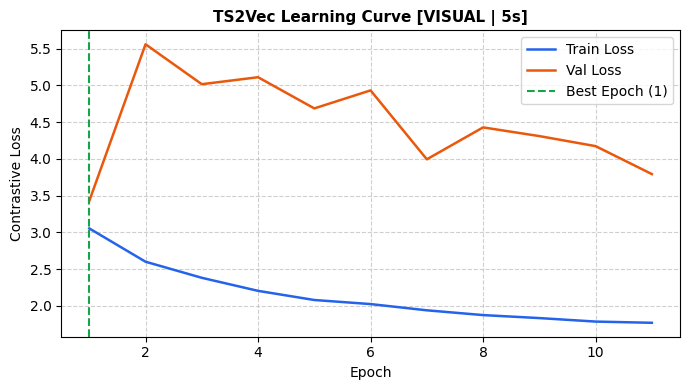

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/5s/ts2vec_learning_curve_visual.png
[visual | 5s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5185, 32)
  - emb_val   shape: (1153, 32)
  - emb_test  shape: (956, 32)
✓ [visual | 5s] 処理完了！所要時間: 77.2 秒 (1.29 分)

▶ [2/6] TS2Vec 被験者完全分離学習 [Modality: VITAL | Window: 5s]
全データ: 7,294 ウィンドウ, 長さ=250, チャネル数=2, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,185 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,153 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  956 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[vital | 5s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=11.5880, val_loss=3.0427 | ★ Best (val loss: 3.0427)
Epoch   2/100: train_loss=3.1994, val_loss=2.7520 | ★ Best (val loss: 2.7520)
Epoch   3/100: train_loss=2.9423, val_loss=2.4846 | ★

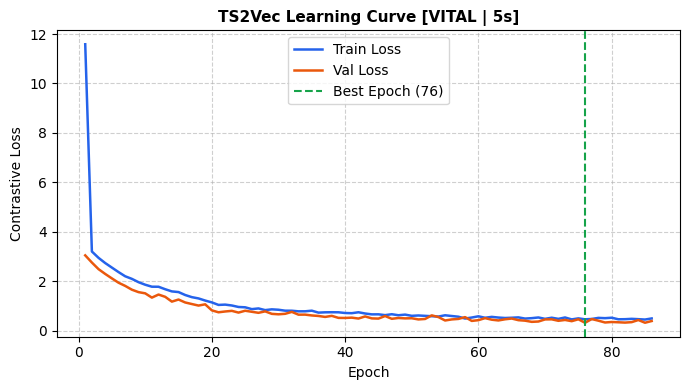

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/5s/ts2vec_learning_curve_vital.png
[vital | 5s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5185, 32)
  - emb_val   shape: (1153, 32)
  - emb_test  shape: (956, 32)
✓ [vital | 5s] 処理完了！所要時間: 449.9 秒 (7.50 分)

▶ [3/6] TS2Vec 被験者完全分離学習 [Modality: VISUAL | Window: 10s]
全データ: 7,230 ウィンドウ, 長さ=500, チャネル数=6, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,140 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,143 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  947 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[visual | 10s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=3.1239, val_loss=4.3748 | ★ Best (val loss: 4.3748)
Epoch   2/100: train_loss=2.6508, val_loss=4.9098 | Patience 1/10
Epoch   3/100: train_loss=2.4710, val_loss=6.3393 | Patience 2/1

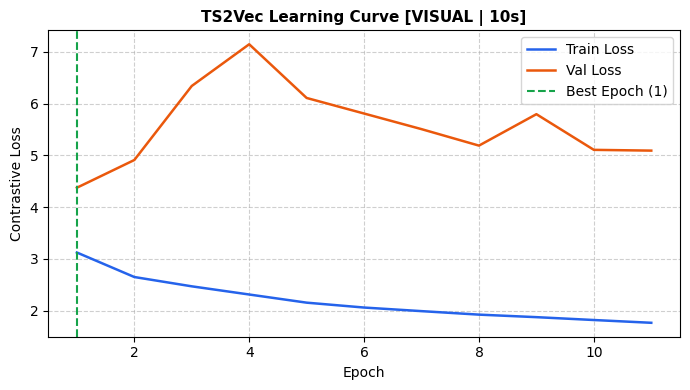

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/10s/ts2vec_learning_curve_visual.png
[visual | 10s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5140, 32)
  - emb_val   shape: (1143, 32)
  - emb_test  shape: (947, 32)
✓ [visual | 10s] 処理完了！所要時間: 81.6 秒 (1.36 分)

▶ [4/6] TS2Vec 被験者完全分離学習 [Modality: VITAL | Window: 10s]
全データ: 7,230 ウィンドウ, 長さ=500, チャネル数=2, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,140 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,143 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  947 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[vital | 10s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=13.5635, val_loss=3.1971 | ★ Best (val loss: 3.1971)
Epoch   2/100: train_loss=3.3769, val_loss=2.9251 | ★ Best (val loss: 2.9251)
Epoch   3/100: train_loss=3.0972, val_loss=2.666

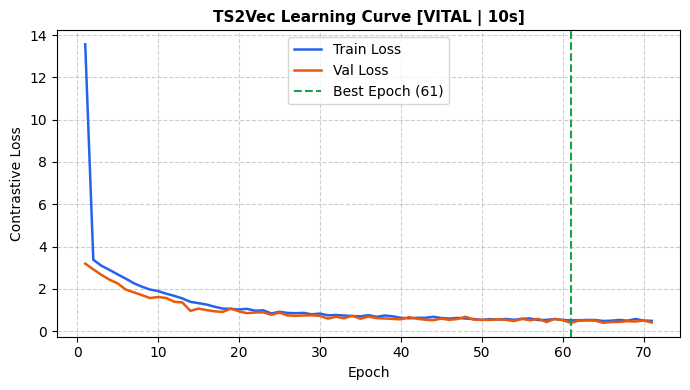

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/10s/ts2vec_learning_curve_vital.png
[vital | 10s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5140, 32)
  - emb_val   shape: (1143, 32)
  - emb_test  shape: (947, 32)
✓ [vital | 10s] 処理完了！所要時間: 474.1 秒 (7.90 分)

▶ [5/6] TS2Vec 被験者完全分離学習 [Modality: VISUAL | Window: 15s]
全データ: 7,170 ウィンドウ, 長さ=750, チャネル数=6, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,095 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,133 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  942 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[visual | 15s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=3.3827, val_loss=3.7130 | ★ Best (val loss: 3.7130)
Epoch   2/100: train_loss=2.8491, val_loss=4.9948 | Patience 1/10
Epoch   3/100: train_loss=2.6375, val_loss=5.3315 | Patience 

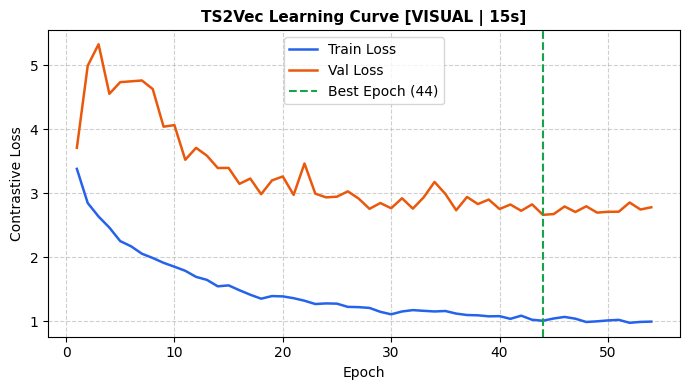

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/15s/ts2vec_learning_curve_visual.png
[visual | 15s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5095, 32)
  - emb_val   shape: (1133, 32)
  - emb_test  shape: (942, 32)
✓ [visual | 15s] 処理完了！所要時間: 514.7 秒 (8.58 分)

▶ [6/6] TS2Vec 被験者完全分離学習 [Modality: VITAL | Window: 15s]
全データ: 7,170 ウィンドウ, 長さ=750, チャネル数=2, 全被験者=13 名

🛡️ [被験者完全分離 完了]
  - Train: 5,095 サンプル | 被験者 (9名): ['1783067552538', '74cOXS5nwF', 'EPu3DMEDU3', 'ESJdSRZW0Z', 'OIArwJxCJx', 'd2G3Tj0tfu', 'gH6tcCjukV', 'pWR7xZebED', 'ybcDeyUlyu']
  - Val:   1,133 サンプル | 被験者 (2名): ['1783067519588', 'H6SaVKMe91']
  - Test:  942 サンプル | 被験者 (2名): ['lII4axQMiZ', 'sTfnnnrGq4']

[vital | 15s] TS2Vec 学習開始 (Train使用, EarlyStopping=True (Patience=10), MaxEpochs=100, BatchSize=32)...
Epoch   1/100: train_loss=10.7426, val_loss=3.1022 | ★ Best (val loss: 3.1022)
Epoch   2/100: train_loss=3.3499, val_loss=2.9219 | ★ Best (val loss: 2.9219)
Epoch   3/100: train_loss=3.0532, val_loss=2.60

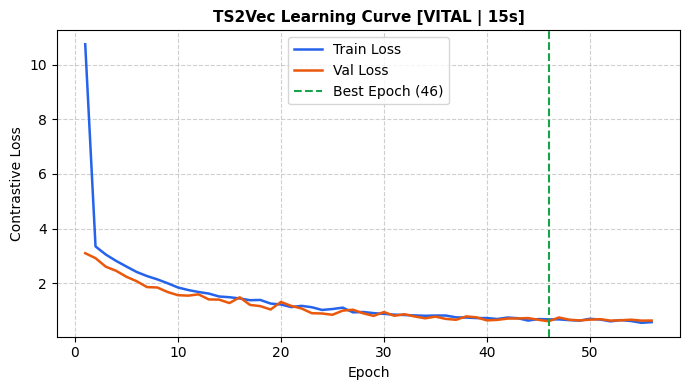

✓ 学習曲線プロットを保存しました: /content/drive/MyDrive/make_ai/data/windowed/15s/ts2vec_learning_curve_vital.png
[vital | 15s] 最良モデルで各 Split をエンコード中...
  - emb_train shape: (5095, 32)
  - emb_val   shape: (1133, 32)
  - emb_test  shape: (942, 32)
✓ [vital | 15s] 処理完了！所要時間: 511.9 秒 (8.53 分)

🎉 全タスク (計 6 件) の被験者完全分離学習・抽出・保存が完了しました！
総所要時間: 2128.3 秒 (35.47 分)


In [ ]:
# @title 🚀 4. 被験者完全分離 (Train/Val/Test) & Train のみでの TS2Vec 学習・潜在表現抽出
# @markdown Test / Val の被験者を事前学習の重み更新から完全に遮断し、厳格なデータリークフリーでモデル学習 (Val 監視 Early Stopping 付き) & 各分割エンコードを実行します。

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

total_start = time.time()
execution_summary = []

for i, task in enumerate(all_tasks, 1):
    modal = task["modality"]
    ws = task["window"]
    x_path = task["x_path"]
    meta_path = task["meta_path"]
    ws_dir = task["ws_dir"]
    modal_dir = task["modal_dir"]

    ws_dir.mkdir(parents=True, exist_ok=True)
    modal_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "=" * 75)
    print(f"▶ [{i}/{len(all_tasks)}] TS2Vec 被験者完全分離学習 [Modality: {modal.upper()} | Window: {ws}]")
    print("=" * 75)

    # --- 1. データのロード ---
    X = np.load(x_path).astype(np.float32)  # [N, T, C]
    meta_df = pd.read_csv(meta_path)
    n_samples, seq_len, input_dims = X.shape

    group_col = GROUP_COL if GROUP_COL in meta_df.columns else "subject_id"
    groups = meta_df[group_col].values
    unique_users = np.unique(groups)
    print(f"全データ: {n_samples:,d} ウィンドウ, 長さ={seq_len}, チャネル数={input_dims}, 全被験者={len(unique_users)} 名")

    # --- 2. 被験者単位 (Group) による Train+Val と Test 分割 ---
    gss_test = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    train_val_idx, test_idx = next(gss_test.split(X, groups=groups))

    # --- 3. Train と Val 分割 ---
    gss_val = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=RANDOM_STATE)
    train_sub_idx, val_sub_idx = next(gss_val.split(X[train_val_idx], groups=groups[train_val_idx]))

    train_idx = train_val_idx[train_sub_idx]
    val_idx = train_val_idx[val_sub_idx]

    train_users = np.unique(groups[train_idx])
    val_users = np.unique(groups[val_idx])
    test_users = np.unique(groups[test_idx])

    print(f"\n🛡️ [被験者完全分離 完了]")
    print(f"  - Train: {len(train_idx):,d} サンプル | 被験者 ({len(train_users)}名): {list(train_users)}")
    print(f"  - Val:   {len(val_idx):,d} サンプル | 被験者 ({len(val_users)}名): {list(val_users)}")
    print(f"  - Test:  {len(test_idx):,d} サンプル | 被験者 ({len(test_users)}名): {list(test_users)}")

    X_train = X[train_idx]
    X_val = X[val_idx]
    X_test = X[test_idx]

    # --- 4. モデル初期化 ---
    model_save_path = model_dir / f"ts2vec_model_{modal}_{ws}.pt"
    model = EarlyStoppingTS2Vec(
        input_dims=input_dims,
        output_dims=OUTPUT_DIMS,
        hidden_dims=HIDDEN_DIMS,
        depth=DEPTH,
        device=DEVICE,
        lr=LR,
        batch_size=BATCH_SIZE,
    )

    # --- 5. TS2Vec 学習 (※ Train で学習し、Val で Early Stopping 監視！) ---
    print(f"\n[{modal} | {ws}] TS2Vec 学習開始 (Train使用, EarlyStopping={EARLY_STOPPING} (Patience={PATIENCE}), MaxEpochs={N_EPOCHS}, BatchSize={BATCH_SIZE})...")
    t_start = time.time()
    loss_log = model.fit(
        X_train,
        val_data=X_val,
        n_epochs=N_EPOCHS,
        patience=PATIENCE if EARLY_STOPPING else None,
        min_delta=MIN_DELTA,
        verbose=True,
    )

    # モデル保存 (最良エポックの重みが復元された状態で保存)
    model.save(str(model_save_path))
    print(f"✓ 最良モデル保存完了 (Best Epoch: {model.best_epoch}): {model_save_path}")

    # 学習曲線の可視化 & 保存
    fig, ax = plt.subplots(figsize=(7, 4), dpi=100)
    epochs_range = range(1, len(model.train_loss_log) + 1)
    ax.plot(epochs_range, model.train_loss_log, label="Train Loss", color="#2563eb", linewidth=1.8)
    if model.val_loss_log:
        ax.plot(epochs_range, model.val_loss_log, label="Val Loss", color="#ea580c", linewidth=1.8)
    if model.best_epoch:
        ax.axvline(model.best_epoch, color="#16a34a", linestyle="--", label=f"Best Epoch ({model.best_epoch})")
    ax.set_title(f"TS2Vec Learning Curve [{modal.upper()} | {ws}]", fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=10)
    ax.set_ylabel("Contrastive Loss", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
    plt.tight_layout()
    curve_path = ws_dir / f"ts2vec_learning_curve_{modal}.png"
    plt.savefig(curve_path)
    plt.show()
    print(f"✓ 学習曲線プロットを保存しました: {curve_path}")

    # --- 6. 各 Split の 32次元潜在表現ベクトル抽出 ---
    print(f"[{modal} | {ws}] 最良モデルで各 Split をエンコード中...")
    emb_train = model.encode(X_train, encoding_window="full_series")
    emb_val = model.encode(X_val, encoding_window="full_series")
    emb_test = model.encode(X_test, encoding_window="full_series")

    print(f"  - emb_train shape: {emb_train.shape}")
    print(f"  - emb_val   shape: {emb_val.shape}")
    print(f"  - emb_test  shape: {emb_test.shape}")

    # --- 7. ファイル保存 (2系統のパスに保存) ---
    # A. ウィンドウ直下 (emb_train_{modal}.npy, emb_val_{modal}.npy, emb_test_{modal}.npy)
    np.save(ws_dir / f"emb_train_{modal}.npy", emb_train)
    np.save(ws_dir / f"emb_val_{modal}.npy", emb_val)
    np.save(ws_dir / f"emb_test_{modal}.npy", emb_test)

    # B. モダリティフォルダ直下 ({modal}/emb_train.npy 等)
    np.save(modal_dir / "emb_train.npy", emb_train)
    np.save(modal_dir / "emb_val.npy", emb_val)
    np.save(modal_dir / "emb_test.npy", emb_test)

    # 分割インデックスとメタデータの保存
    np.savez(
        ws_dir / "split_indices.npz",
        train_idx=train_idx,
        val_idx=val_idx,
        test_idx=test_idx,
    )
    np.savez(
        modal_dir / "split_indices.npz",
        train_idx=train_idx,
        val_idx=val_idx,
        test_idx=test_idx,
    )
    meta_df.iloc[train_idx].to_csv(ws_dir / "meta_train.csv", index=False)
    meta_df.iloc[val_idx].to_csv(ws_dir / "meta_val.csv", index=False)
    meta_df.iloc[test_idx].to_csv(ws_dir / "meta_test.csv", index=False)
    meta_df.iloc[train_idx].to_csv(modal_dir / "meta_train.csv", index=False)
    meta_df.iloc[val_idx].to_csv(modal_dir / "meta_val.csv", index=False)
    meta_df.iloc[test_idx].to_csv(modal_dir / "meta_test.csv", index=False)

    elapsed = time.time() - t_start
    print(f"✓ [{modal} | {ws}] 処理完了！所要時間: {elapsed:.1f} 秒 ({elapsed/60:.2f} 分)")

    execution_summary.append({
        "modality": modal,
        "window": ws,
        "input_channels": input_dims,
        "output_dims": OUTPUT_DIMS,
        "train_samples": len(train_idx),
        "val_samples": len(val_idx),
        "test_samples": len(test_idx),
        "epochs_run": len(model.train_loss_log),
        "best_epoch": model.best_epoch,
        "best_loss": round(float(model.best_loss), 4) if model.best_loss is not None else None,
        "elapsed_sec": round(elapsed, 1),
        "final_loss": round(float(loss_log[-1]), 4) if loss_log else None,
        "model_path": str(model_save_path.name),
    })

total_elapsed = time.time() - total_start
print("\n" + "=" * 75)
print(f"🎉 全タスク (計 {len(all_tasks)} 件) の被験者完全分離学習・抽出・保存が完了しました！")
print(f"総所要時間: {total_elapsed:.1f} 秒 ({total_elapsed/60:.2f} 分)")
print("=" * 75)


In [ ]:
# @title 📊 5. 実行結果サマリー & 生成されたモデル・出力ファイル一覧
summary_df = pd.DataFrame(execution_summary)
print("【実行サマリー】")
display(summary_df)

print("\n【💾 生成された TS2Vec モデル一覧】")
for p in sorted(model_dir.glob("*.pt")):
    size_mb = p.stat().st_size / (1024 * 1024)
    print(f"   - {p.name:<32} ({size_mb:.2f} MB)")

print("\n【📊 生成された潜在表現埋め込み (Embeddings) ファイル一覧】")
for ws in TARGET_WINDOWS:
    ws_dirs = [
        base_dir / "preprocess" / "data" / "windowed" / ws,
        base_dir / "data" / "windowed" / ws,
    ]
    w_dir = next((d for d in ws_dirs if d.exists()), ws_dirs[0])
    print(f"\n📁 {w_dir}:")
    for p in sorted(w_dir.glob("emb_*.npy")):
        size_mb = p.stat().st_size / (1024 * 1024)
        print(f"   - {p.name:<25} ({size_mb:.2f} MB)")
    for modal in TARGET_MODALITIES:
        m_sub = w_dir / modal
        if m_sub.exists():
            print(f"   📁 サブフォルダ {modal}/:")
            for p in sorted(m_sub.glob("emb_*.npy")):
                size_mb = p.stat().st_size / (1024 * 1024)
                print(f"       - {p.name:<21} ({size_mb:.2f} MB)")


【実行サマリー】


,modality,window,input_channels,output_dims,train_samples,val_samples,test_samples,epochs_run,best_epoch,best_loss,elapsed_sec,final_loss,model_path
0,visual,5s,6,32,5185,1153,956,11,1,3.4281,77.2,1.7704,ts2vec_model_visual_5s.pt
1,vital,5s,2,32,5185,1153,956,86,76,0.3136,449.9,0.4898,ts2vec_model_vital_5s.pt
2,visual,10s,6,32,5140,1143,947,11,1,4.3748,81.6,1.7668,ts2vec_model_visual_10s.pt
3,vital,10s,2,32,5140,1143,947,71,61,0.4000,474.1,0.4938,ts2vec_model_vital_10s.pt
4,visual,15s,6,32,5095,1133,942,54,44,2.6638,514.7,0.9942,ts2vec_model_visual_15s.pt
5,vital,15s,2,32,5095,1133,942,56,46,0.6146,511.9,0.5829,ts2vec_model_vital_15s.pt



【💾 生成された TS2Vec モデル一覧】
   - ts2vec_model_visual_10s.pt       (0.13 MB)
   - ts2vec_model_visual_15s.pt       (0.13 MB)
   - ts2vec_model_visual_5s.pt        (0.13 MB)
   - ts2vec_model_vital_10s.pt        (0.13 MB)
   - ts2vec_model_vital_15s.pt        (0.13 MB)
   - ts2vec_model_vital_5s.pt         (0.13 MB)

【📊 生成された潜在表現埋め込み (Embeddings) ファイル一覧】

📁 /content/drive/MyDrive/make_ai/data/windowed/5s:
   - emb_test_visual.npy       (0.12 MB)
   - emb_test_vital.npy        (0.12 MB)
   - emb_train_visual.npy      (0.63 MB)
   - emb_train_vital.npy       (0.63 MB)
   - emb_val_visual.npy        (0.14 MB)
   - emb_val_vital.npy         (0.14 MB)
   📁 サブフォルダ visual/:
       - emb_test.npy          (0.12 MB)
       - emb_train.npy         (0.63 MB)
       - emb_val.npy           (0.14 MB)
   📁 サブフォルダ vital/:
       - emb_test.npy          (0.12 MB)
       - emb_train.npy         (0.63 MB)
       - emb_val.npy           (0.14 MB)

📁 /content/drive/MyDrive/make_ai/data/windowed/10s:
   - emb_te